In [56]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import make_regression, make_blobs
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

(100, 1) (100,)


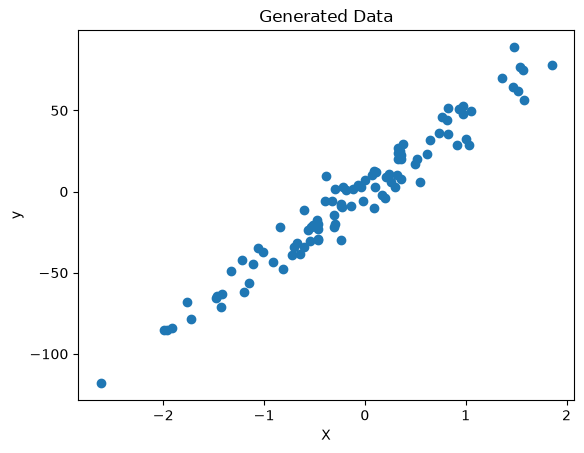

In [13]:
X, y = make_regression(n_samples=100,
                       n_features=1,
                       noise=10,
                       random_state=42)
print(X.shape, y.shape)
plt.scatter(X, y)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Generated Data')
plt.show()

In [24]:
X, y = make_blobs(n_samples=200,
                   centers=2,
                   cluster_std=1.5,
                   n_features=2, random_state=42)
print(X.shape, y.shape)

(200, 2) (200,)


In [26]:
sci_kit_internal_data = load_breast_cancer()
print(sci_kit_internal_data.keys())
breast_cancer_data = pd.DataFrame(sci_kit_internal_data.data,
	                columns=sci_kit_internal_data.feature_names)
breast_cancer_data['Diagnosis'] = sci_kit_internal_data.target
breast_cancer_data.to_csv('breast_cancer_data.csv', index=False)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [29]:
bc_data = pd.read_csv('breast_cancer_data.csv')
diagnosis_counts = bc_data['Diagnosis'].value_counts()
diagnosis_percentages = diagnosis_counts / len(bc_data) * 100
print(diagnosis_counts, diagnosis_percentages)

Diagnosis
1    357
0    212
Name: count, dtype: int64 Diagnosis
1    62.741652
0    37.258348
Name: count, dtype: float64


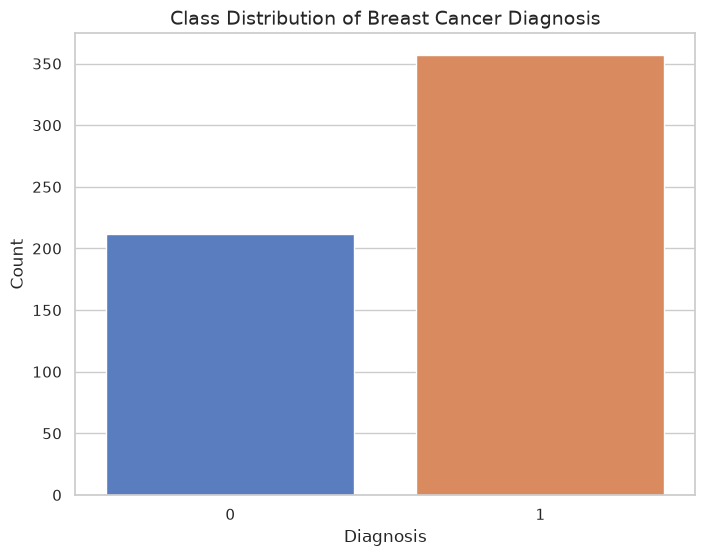

In [30]:
diagnosis_df = diagnosis_counts.reset_index()
diagnosis_df.columns = ['Diagnosis', 'Count']
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=diagnosis_df,
	                x='Diagnosis',
	                y='Count',
	                hue='Diagnosis',
	                palette='muted',
	                legend=False)
plt.title('Class Distribution of Breast Cancer Diagnosis', fontsize=14)
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

In [31]:
bc_data.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Diagnosis                  0
dtype: int64

In [40]:
bc_data.fillna(bc_data.median(), inplace=True)
scaler = StandardScaler()
num_features = bc_data.columns.drop('Diagnosis')
print("Numerical features:", num_features)
bc_data[num_features] = scaler.fit_transform(bc_data[num_features])
print(bc_data.head())


Numerical features: Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='str')
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909    

In [49]:
X = bc_data.drop('Diagnosis', axis=1)
y = bc_data['Diagnosis']
split_prop = round(float(1 - 0.8),1)
X_train, X_test, y_train, y_test = train_test_split(
	   X,
	   y,
	   test_size=split_prop,
	   random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
class_preds = model.predict(X_test)
prob_preds = model.predict_proba(X_test)
model.score(X_test, y_test)

0.9736842105263158

In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from time import time
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, accuracy_score)
my_classifiers = {
     "Logistic Regression": LogisticRegression(max_iter=1000),
     "Random Forest": RandomForestClassifier(random_state=42),
     "SVM": CalibratedClassifierCV(SVC()),
     "KNN": KNeighborsClassifier(),
     "Decision Tree": DecisionTreeClassifier(random_state=42),
     "Naive Bayes": GaussianNB(),
     "LDA": LinearDiscriminantAnalysis()
}
model_results = {
     "Model": [],
     "Accuracy": [],
     "Precision": [],
     "Recall": [],
     "F1 Score": [],
     "Training Time (s)": [],
     "Predictions": [],
     "Probabilities": []
}

for model_name, model in my_classifiers.items():
  start_timer = time()
  model.fit(X_train, y_train)
  end_model_timer = time()

  y_pred = model.predict(X_test)
  y_prob = model.predict_proba(X_test)
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  train_time = end_model_timer - start_timer

  model_results["Model"].append(model_name)
  model_results["Accuracy"].append(accuracy)
  model_results["Precision"].append(precision)
  model_results["Recall"].append(recall)
  model_results["F1 Score"].append(f1)
  model_results["Training Time (s)"].append(train_time)
  model_results["Predictions"].append(y_pred)
  model_results["Probabilities"].append(y_prob)

In [60]:
model_scores_summary = model_results.copy()
model_scores_summary.pop('Predictions', None)
model_scores_summary.pop('Probabilities', None)

[array([[1.14654306e-01, 8.85345694e-01],
        [9.99991258e-01, 8.74244925e-06],
        [9.96935812e-01, 3.06418819e-03],
        [5.01521801e-04, 9.99498478e-01],
        [5.98499000e-05, 9.99940150e-01],
        [1.00000000e+00, 9.10729855e-11],
        [9.99999998e-01, 1.50144666e-09],
        [9.64771580e-01, 3.52284199e-02],
        [3.79164333e-01, 6.20835667e-01],
        [7.45367462e-04, 9.99254633e-01],
        [4.93966092e-02, 9.50603391e-01],
        [9.87635123e-01, 1.23648774e-02],
        [6.00401864e-03, 9.93995981e-01],
        [8.54448163e-01, 1.45551837e-01],
        [1.61667308e-03, 9.98383327e-01],
        [9.99166904e-01, 8.33096440e-04],
        [1.84326251e-03, 9.98156737e-01],
        [1.13474951e-05, 9.99988653e-01],
        [8.16917486e-07, 9.99999183e-01],
        [9.99998888e-01, 1.11170313e-06],
        [8.39246705e-02, 9.16075330e-01],
        [9.90428726e-03, 9.90095713e-01],
        [9.99999996e-01, 4.29067033e-09],
        [7.70484841e-05, 9.9992295

In [61]:
results_df = pd.DataFrame(model_scores_summary)

In [ ]:
multi_model_visualizer(results_df,
colors=["#2b68a5","#1af298","mediumseagreen", "mediumpurple", "gold"])